In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
 
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay,
)

In [3]:
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df["target"] = data.target  # 0 = Malignant, 1 = Benign
df["diagnosis"] = df["target"].map({0: "Malignant", 1: "Benign"})

In [4]:
df.drop(columns="diagnosis").to_csv("breast_cancer_data.csv", index=False)
 
print("Shape:", df.shape)
print("\nFirst 5 rows:\n", df.head())
print("\nClass distribution:\n", df["diagnosis"].value_counts())

Shape: (569, 32)

First 5 rows:
    mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst perimeter  worst area

In [5]:
print("\nMissing values:", int(df.isnull().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
 
X = df[data.feature_names]
y = df["target"]
 
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


Missing values: 0
Duplicate rows: 0


In [7]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, random_state=42)),
    ]),
    "Random Forest": Pipeline([
        ("clf", RandomForestClassifier(n_estimators=200, random_state=42)),
    ]),
    "Decision Tree": Pipeline([
        ("clf", DecisionTreeClassifier(max_depth=5, random_state=42)),
    ]),
}
 
results = []
fitted = {}

In [8]:
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    cv = cross_val_score(model, X, y, cv=5, scoring="accuracy")
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-Score": f1_score(y_test, pred),
        "CV Accuracy (5-fold)": cv.mean(),
    })
    fitted[name] = (model, pred)
 
results_df = pd.DataFrame(results).sort_values("Accuracy", ascending=False)
print("\n=== Model Comparison ===")
print(results_df.round(4).to_string(index=False))


=== Model Comparison ===
              Model  Accuracy  Precision  Recall  F1-Score  CV Accuracy (5-fold)
Logistic Regression    0.9825     0.9861  0.9861    0.9861                0.9807
      Random Forest    0.9561     0.9589  0.9722    0.9655                0.9578
      Decision Tree    0.9211     0.9565  0.9167    0.9362                0.9191


In [9]:
best_name = results_df.iloc[0]["Model"]
best_model, best_pred = fitted[best_name]
 
print(f"\nBest model: {best_name}")
print("\nConfusion Matrix:\n", confusion_matrix(y_test, best_pred))
print("\nClassification Report:\n",
      classification_report(y_test, best_pred,
                            target_names=["Malignant", "Benign"]))


Best model: Logistic Regression

Confusion Matrix:
 [[41  1]
 [ 1 71]]

Classification Report:
               precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



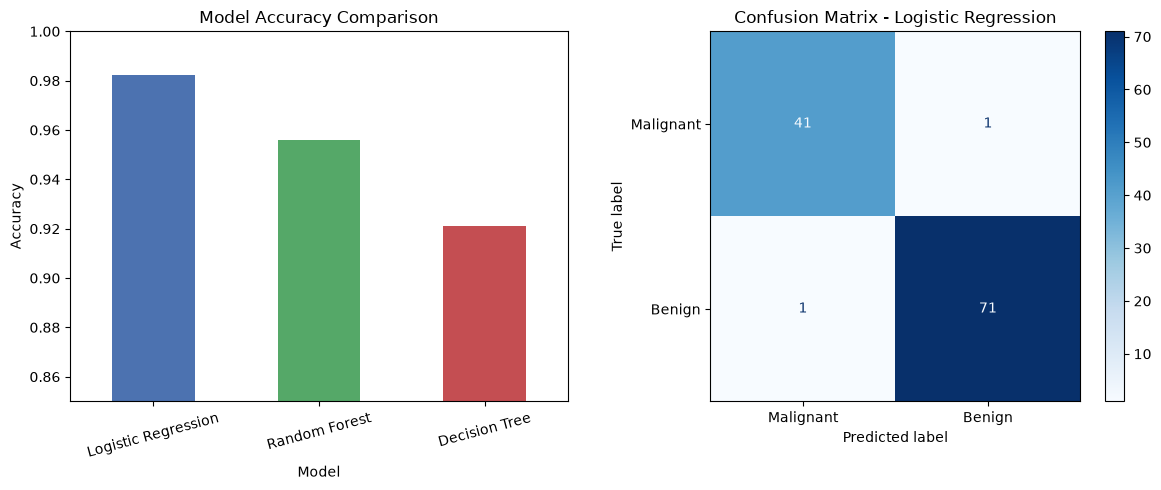

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
 
results_df.set_index("Model")["Accuracy"].plot(
    kind="bar", ax=ax[0], color=["#4C72B0", "#55A868", "#C44E52"]
)
ax[0].set_title("Model Accuracy Comparison")
ax[0].set_ylim(0.85, 1.0)
ax[0].set_ylabel("Accuracy")
ax[0].tick_params(axis="x", rotation=15)
 
ConfusionMatrixDisplay.from_predictions(
    y_test, best_pred, display_labels=["Malignant", "Benign"],
    ax=ax[1], cmap="Blues"
)
ax[1].set_title(f"Confusion Matrix - {best_name}")
 
plt.tight_layout()
plt.savefig("results.png", dpi=150)
plt.show()

In [11]:
rf = fitted["Random Forest"][0].named_steps["clf"]
imp = pd.Series(rf.feature_importances_, index=data.feature_names)
print("\nTop 10 important features (Random Forest):")
print(imp.sort_values(ascending=False).head(10).round(4))


Top 10 important features (Random Forest):
worst perimeter         0.1331
worst area              0.1281
worst concave points    0.1081
mean concave points     0.0944
worst radius            0.0906
mean radius             0.0587
mean perimeter          0.0552
mean area               0.0499
mean concavity          0.0462
worst concavity         0.0354
dtype: float64


In [12]:
sample = X_test.iloc[[0]]
label = best_model.predict(sample)[0]
print("\nSample prediction:", "Benign" if label == 1 else "Malignant",
      "| Actual:", "Benign" if y_test.iloc[0] == 1 else "Malignant")


Sample prediction: Malignant | Actual: Malignant
